Total matches: 4000, good after ratio test: 108
Homography matrix:
 [[ 2.93277283e+00  7.24615564e-03 -4.95813393e+01]
 [ 1.30018182e-01  2.81405077e+00 -4.12157693e+01]
 [ 5.55746495e-05 -8.56070553e-05  1.00000000e+00]]


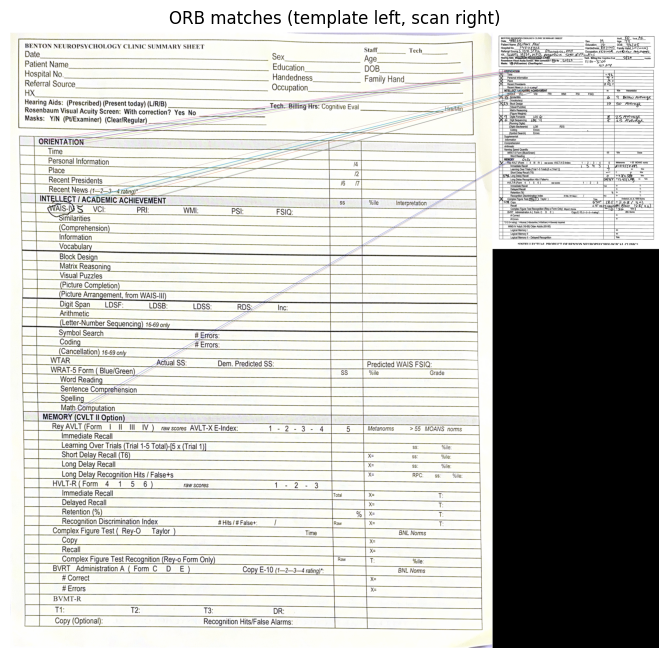

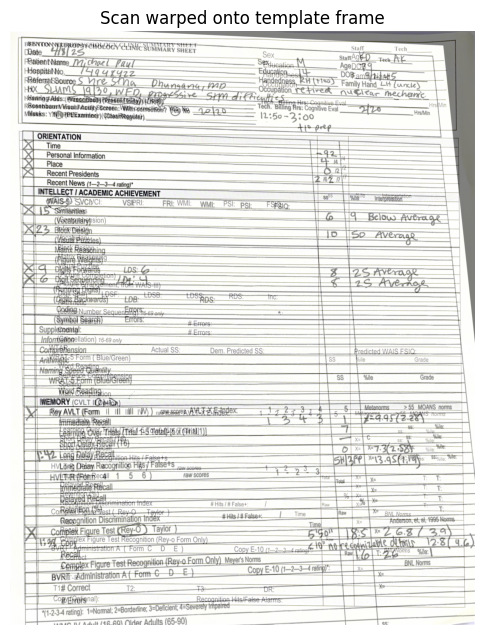

In [11]:
import cv2
import fitz
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---------- user‑editable paths ------------------------------------------
scan_pdf   = Path('../case_outputs/sheets/00000.pdf')  # scanned sheet
page_idx   = 0                                               # zero‑based page index
template   = Path('../template.jpg')                     # blank reference image
# -------------------------------------------------------------------------

BASE_DPI   = 150
dpi_render = 150

# ---------- load scan page as RGB numpy ----------------------------------
doc  = fitz.open(scan_pdf)
page = doc[page_idx]
pix  = page.get_pixmap(dpi=dpi_render)                       # full page

scan = np.frombuffer(pix.samples, np.uint8).reshape(
           pix.height, pix.width, pix.n)                     # H×W×3 RGB
scan_bgr = cv2.cvtColor(scan, cv2.COLOR_RGB2BGR)

# ---------- load template -------------------------------------------------
tmpl_bgr = cv2.imread(str(template))
if tmpl_bgr is None:
    raise FileNotFoundError(f"Template image not found: {template}")

# ---------- ORB feature detection ----------------------------------------
orb = cv2.ORB_create(4000)
kp_t, des_t = orb.detectAndCompute(cv2.cvtColor(tmpl_bgr, cv2.COLOR_BGR2GRAY), None)
kp_s, des_s = orb.detectAndCompute(cv2.cvtColor(scan_bgr, cv2.COLOR_BGR2GRAY), None)

matcher = cv2.BFMatcher(cv2.NORM_HAMMING)
matches = matcher.knnMatch(des_t, des_s, k=2)

# Lowe ratio test
good = [m[0] for m in matches if len(m)==2 and m[0].distance < 0.75*m[1].distance]

print(f"Total matches: {len(matches)}, good after ratio test: {len(good)}")

if len(good) < 10:
    raise RuntimeError("Not enough matches to build homography.")

src_pts = np.float32([kp_t[m.queryIdx].pt for m in good])
dst_pts = np.float32([kp_s[m.trainIdx].pt for m in good])

H, mask = cv2.findHomography(dst_pts, src_pts, cv2.RANSAC, 5.0)
print("Homography matrix:\n", H)

# ---------- visualise matches --------------------------------------------
# keep every good match
inliers = [m for m, msk in zip(good, mask.ravel()) if msk]
match_img = cv2.drawMatches(
    tmpl_bgr, kp_t,
    scan_bgr, kp_s,
    inliers,                         # full inlier list
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)


plt.figure(figsize=(14,8))
plt.title("ORB matches (template left, scan right)")
plt.imshow(cv2.cvtColor(match_img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

# ---------- warp scan to template frame & overlay grid -------------------
h_tmpl, w_tmpl = tmpl_bgr.shape[:2]
aligned = cv2.warpPerspective(scan_bgr, H, (w_tmpl, h_tmpl))

overlay = cv2.addWeighted(tmpl_bgr, 0.5, aligned, 0.5, 0)

plt.figure(figsize=(6,10))
plt.title("Scan warped onto template frame")
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()